# **Prepare MNIST Data**

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [ ]:
# Training parameters
batch_size = 64
learning_rate = 0.001
num_epochs = 5

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cpu


In [ ]:
transform = transforms.Compose([
    transforms.ToTensor()
])

In [ ]:
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)
#Ý nghĩa
#train=True
#→ lấy 60,000 ảnh để TRAIN

#train=False
#→ lấy 10,000 ảnh để TEST

100%|██████████| 9.91M/9.91M [00:00<00:00, 58.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.71MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.7MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.30MB/s]


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Testing images :", len(test_dataset))

Training images: 60000
Testing images : 10000


In [ ]:
image, label = train_dataset[1]

print("Image shape:", image.shape)
print("Label:", label)
#Ý nghĩa
# 1: grayscale channel
# 28: Height
# 28: Width

Image shape: torch.Size([1, 28, 28])
Label: 0


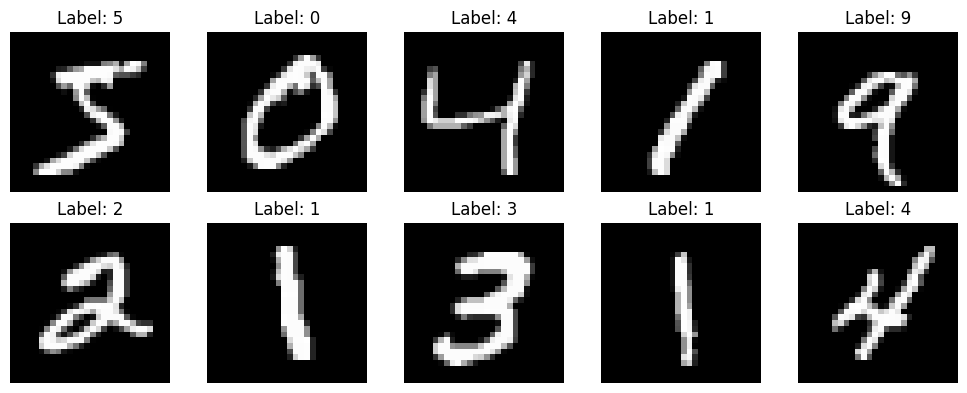

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# **Build TinyCNN Model**

In [ ]:
class TinyCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Convolution layer
        self.conv = nn.Conv2d(
            in_channels=1,
            out_channels=1,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )

        # Activation function
        self.relu = nn.ReLU()

        # Fully Connected layer
        self.fc = nn.Linear(
            28 * 28,
            10
        )

    def forward(self, x):
        x = self.conv(x)
        x = self.relu(x)

        x = x.view(x.size(0), -1)

        x = self.fc(x)

        return x

In [ ]:
model = TinyCNN().to(device)

print(model)

TinyCNN(
  (conv): Conv2d(1, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (relu): ReLU()
  (fc): Linear(in_features=784, out_features=10, bias=True)
)


In [ ]:
image, label = train_dataset[0]

x = image.unsqueeze(0).to(device)

conv_output = model.conv(x)
relu_output = model.relu(conv_output)

print("Input shape       :", x.shape)
print("Conv output shape :", conv_output.shape)
print("ReLU output shape :", relu_output.shape)

Input shape       : torch.Size([1, 1, 28, 28])
Conv output shape : torch.Size([1, 1, 28, 28])
ReLU output shape : torch.Size([1, 1, 28, 28])


In [ ]:
print("Conv weight shape:")
print(model.conv.weight.shape)

print("\nCurrent convolution weights:")
print(model.conv.weight)

Conv weight shape:
torch.Size([1, 1, 3, 3])

Current convolution weights:
Parameter containing:
tensor([[[[-0.1833,  0.2997, -0.0089],
          [-0.1179,  0.0608,  0.0334],
          [ 0.0592, -0.0172,  0.0746]]]], requires_grad=True)


# **Define Loss Function and Optimizer**

In [ ]:
# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


# **Train TinyCNN Model**

In [ ]:
# Train TinyCNN model

for epoch in range(num_epochs):

    # Chuyển model sang chế độ training
    model.train()

    total_loss = 0.0

    for images, labels in train_loader:

        # Đưa dữ liệu lên CPU/GPU
        images = images.to(device)
        labels = labels.to(device)

        # Xóa gradient của lần train trước
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Tính loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Cập nhật weight
        optimizer.step()

        # Cộng loss để tính trung bình
        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"- Loss: {average_loss:.4f}"
    )

print("Training completed!")

Epoch [1/5] - Loss: 0.4823
Epoch [2/5] - Loss: 0.3013
Epoch [3/5] - Loss: 0.2882
Epoch [4/5] - Loss: 0.2811
Epoch [5/5] - Loss: 0.2764
Training completed!


# **Evaluate Model Accuracy**

In [ ]:
# Evaluate TinyCNN accuracy on test dataset

model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Lấy class có score lớn nhất
        _, predicted = torch.max(outputs, 1)

        # Tổng số ảnh
        total += labels.size(0)

        # Đếm số ảnh dự đoán đúng
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print("Correct predictions:", correct)
print("Total test images   :", total)
print(f"Test Accuracy       : {accuracy:.2f}%")

Correct predictions: 9237
Total test images   : 10000
Test Accuracy       : 92.37%


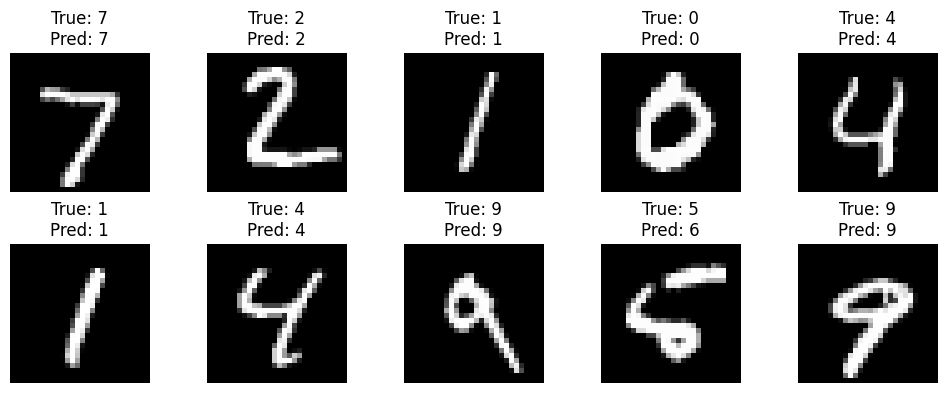

In [ ]:
import matplotlib.pyplot as plt

model.eval()

images, labels = next(iter(test_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):

    ax.imshow(images[i].cpu().squeeze(), cmap="gray")

    ax.set_title(
        f"True: {labels[i].item()}\n"
        f"Pred: {predicted[i].item()}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

# **Test Prediction with a Single MNIST Image.**

In [ ]:
# Test prediction with a single MNIST image

model.eval()

# Lấy 1 ảnh từ test dataset
test_image, true_label = test_dataset[0]

# Thêm batch dimension
input_image = test_image.unsqueeze(0).to(device)

# Dự đoán
with torch.no_grad():
    output = model(input_image)

# Lấy class có score lớn nhất
_, predicted_label = torch.max(output, 1)

print("True label     :", true_label)
print("Predicted label:", predicted_label.item())

True label     : 7
Predicted label: 7


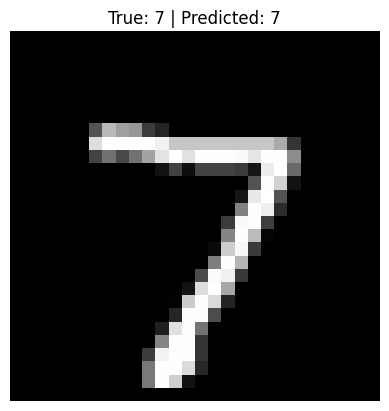

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(test_image.squeeze(), cmap="gray")
plt.title(
    f"True: {true_label} | Predicted: {predicted_label.item()}"
)
plt.axis("off")
plt.show()

In [ ]:
print("Original image shape :", test_image.shape)
print("Model input shape    :", input_image.shape)

Original image shape : torch.Size([1, 28, 28])
Model input shape    : torch.Size([1, 1, 28, 28])


In [ ]:
print(test_image)

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,

In [ ]:
print("Number of activations:", test_image.numel())

activation_float = test_image.flatten()

print("Activation vector shape:", activation_float.shape)
print("First 30 activations:")
print(activation_float[:30])

Number of activations: 784
Activation vector shape: torch.Size([784])
First 30 activations:
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0.])


In [ ]:
model.eval()

with torch.no_grad():
    conv_output = model.conv(input_image)
    relu_output = model.relu(conv_output)

print("Input shape       :", input_image.shape)
print("Conv output shape :", conv_output.shape)
print("ReLU output shape :", relu_output.shape)

Input shape       : torch.Size([1, 1, 28, 28])
Conv output shape : torch.Size([1, 1, 28, 28])
ReLU output shape : torch.Size([1, 1, 28, 28])


In [ ]:
print("Conv output values:", conv_output.numel())
print("ReLU output values:", relu_output.numel())

Conv output values: 784
ReLU output values: 784


# **Extract Convolution Weights**

In [ ]:
conv_weight = model.conv.weight.detach().cpu()

print("Convolution weight shape:")
print(conv_weight.shape)

print("\nConvolution weights:")
print(conv_weight)

Convolution weight shape:
torch.Size([1, 1, 3, 3])

Convolution weights:
tensor([[[[-0.1326,  0.5959,  0.1973],
          [ 0.1429,  0.4702,  0.3581],
          [ 0.2104,  0.2078,  0.2652]]]])


In [ ]:
kernel_float = conv_weight[0, 0]

print("Trained 3x3 kernel:")
print(kernel_float)

Trained 3x3 kernel:
tensor([[-0.1326,  0.5959,  0.1973],
        [ 0.1429,  0.4702,  0.3581],
        [ 0.2104,  0.2078,  0.2652]])


In [ ]:
weight_float = kernel_float.flatten()

print("Flattened weights:")
print(weight_float)

print("Number of weights:", weight_float.numel())

Flattened weights:
tensor([-0.1326,  0.5959,  0.1973,  0.1429,  0.4702,  0.3581,  0.2104,  0.2078,
         0.2652])
Number of weights: 9


In [ ]:
for i, w in enumerate(weight_float):
    print(f"Weight[{i}] = {w.item():.6f}")

Weight[0] = -0.132621
Weight[1] = 0.595851
Weight[2] = 0.197338
Weight[3] = 0.142923
Weight[4] = 0.470177
Weight[5] = 0.358077
Weight[6] = 0.210355
Weight[7] = 0.207789
Weight[8] = 0.265217


In [ ]:
print("Weight dtype:", weight_float.dtype)

Weight dtype: torch.float32


In [ ]:
import numpy as np

np.savetxt(
    "conv_weight_float.txt",
    weight_float.numpy(),
    fmt="%.8f"
)

print("Saved: conv_weight_float.txt")

Saved: conv_weight_float.txt


# **Quantize Weight and Activation to INT8**

In [ ]:
# Quantize convolution weights Float32 -> INT8

weight_max = weight_float.abs().max()

# Avoid division by zero for an all-zero kernel.
if not torch.isfinite(weight_float).all():
    raise ValueError("Weights contain NaN or Inf")
weight_scale = (weight_max / 127.0 if weight_max.item() > 0
                else torch.tensor(1.0, dtype=weight_float.dtype))

weight_int8 = torch.round(
    weight_float / weight_scale
).clamp(-127, 127).to(torch.int8)

print("Weight scale:", weight_scale.item())

print("\nFloat32 weights:")
print(weight_float)

print("\nINT8 weights:")
print(weight_int8)

print("\nWeight dtype:", weight_int8.dtype)

Weight scale: 0.004691737703979015

Float32 weights:
tensor([-0.1326,  0.5959,  0.1973,  0.1429,  0.4702,  0.3581,  0.2104,  0.2078,
         0.2652])

INT8 weights:
tensor([-28, 127,  42,  30, 100,  76,  45,  44,  57], dtype=torch.int8)

Weight dtype: torch.int8


In [ ]:
# Quantize test image / activation Float32 -> INT8

activation_scale = 1.0 / 127.0

activation_int8 = torch.round(
    test_image / activation_scale
).clamp(0, 127).to(torch.int8)

print("Activation scale:", activation_scale)

print("Activation shape:", activation_int8.shape)

print("Activation dtype:", activation_int8.dtype)

print("Number of activations:", activation_int8.numel())

Activation scale: 0.007874015748031496
Activation shape: torch.Size([1, 28, 28])
Activation dtype: torch.int8
Number of activations: 784


In [ ]:
activation_vector_int8 = activation_int8.flatten()

print("First 50 INT8 activations:")
print(activation_vector_int8[:50])

First 50 INT8 activations:
tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0], dtype=torch.int8)


In [ ]:
activation_dequant = activation_int8.float() * activation_scale

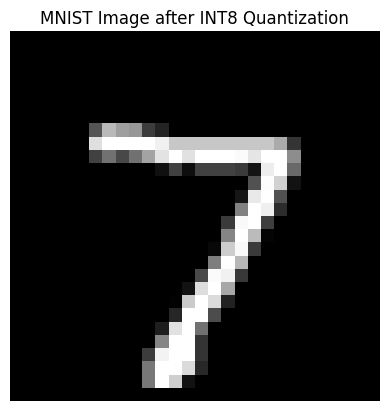

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(
    activation_dequant.squeeze(),
    cmap="gray"
)

plt.title("MNIST Image after INT8 Quantization")
plt.axis("off")
plt.show()

In [ ]:
import numpy as np

np.savetxt(
    "test_activation_int8.txt",
    activation_vector_int8.cpu().numpy(),
    fmt="%d"
)

print("Saved: test_activation_int8.txt")

Saved: test_activation_int8.txt


In [ ]:
np.savetxt(
    "conv_weight_int8.txt",
    weight_int8.cpu().numpy(),
    fmt="%d"
)

print("Saved: conv_weight_int8.txt")

Saved: conv_weight_int8.txt


In [ ]:
# Save quantization parameters for RTL / software reference
with open("quantization_params.txt", "w") as f:
    f.write(f"activation_scale = {activation_scale}\n")
    f.write(f"weight_scale = {weight_scale.item()}\n")
    f.write("activation_zero_point = 0\n")
    f.write("weight_zero_point = 0\n")

print("Saved: quantization_params.txt")


Saved: quantization_params.txt


In [ ]:
import torch.nn.functional as F

# Chuẩn bị input INT8 dưới dạng số nguyên lớn hơn để tránh overflow
x_int = activation_int8.to(torch.int32).unsqueeze(0)

# Weight: [1,1,3,3]
w_int = weight_int8.reshape(1, 1, 3, 3).to(torch.int32)

# Padding = 1
x_pad = F.pad(
    x_int,
    (1, 1, 1, 1),
    mode="constant",
    value=0
)

# Tự tính convolution integer
output_int32 = torch.zeros(
    (1, 1, 28, 28),
    dtype=torch.int32
)

for r in range(28):
    for c in range(28):

        patch = x_pad[
            0, 0,
            r:r+3,
            c:c+3
        ]

        output_int32[0, 0, r, c] = torch.sum(
            patch * w_int[0, 0]
        )

print("Hardware-like output shape:", output_int32.shape)
print("Output dtype:", output_int32.dtype)
print("Number of outputs:", output_int32.numel())

Hardware-like output shape: torch.Size([1, 1, 28, 28])
Output dtype: torch.int32
Number of outputs: 784


In [ ]:
relu_output_int32 = torch.clamp(
    output_int32,
    min=0
)

print("Before ReLU:")
print(output_int32[0, 0, :5, :5])

print("\nAfter ReLU:")
print(relu_output_int32[0, 0, :5, :5])

Before ReLU:
tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

After ReLU:
tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)


# **Final Validation and Export for RTL Verification**


In [ ]:
# Check that the integer convolution really contains useful non-zero data
print("Output MIN:", output_int32.min().item())
print("Output MAX:", output_int32.max().item())
print("Non-zero outputs:", torch.count_nonzero(output_int32).item())

print("\nAfter ReLU MIN:", relu_output_int32.min().item())
print("After ReLU MAX:", relu_output_int32.max().item())
print("After ReLU non-zero:", torch.count_nonzero(relu_output_int32).item())


Output MIN: -1814
Output MAX: 63113
Non-zero outputs: 206

After ReLU MIN: 0
After ReLU MAX: 63113
After ReLU non-zero: 188


In [ ]:
# Save golden outputs for future Cocotb / RTL comparison
np.savetxt(
    "golden_conv_output_int32.txt",
    output_int32.flatten().cpu().numpy(),
    fmt="%d"
)

np.savetxt(
    "golden_relu_output_int32.txt",
    relu_output_int32.flatten().cpu().numpy(),
    fmt="%d"
)

print("Saved: golden_conv_output_int32.txt")
print("Saved: golden_relu_output_int32.txt")


Saved: golden_conv_output_int32.txt
Saved: golden_relu_output_int32.txt


In [ ]:
# Save a LOCAL checkpoint. Download or copy the export ZIP below before runtime deletion.
torch.save(model.state_dict(), "tinycnn_mnist.pth")
print("Saved: tinycnn_mnist.pth")

Saved: tinycnn_mnist.pth


# **RTL Readiness: Validation, Test Vectors and Export**

Phần bổ sung này giữ nguyên kiến trúc và quy trình training. Nếu runtime vẫn còn
các biến từ lần chạy trước, chạy phần lượng tử hóa và golden output rồi chạy các cell
bên dưới; không cần train lại. Nếu runtime đã mất, phải khôi phục checkpoint hoặc
chạy lại notebook. Lần chạy training mới có thể tạo weight và accuracy khác.

**Hợp đồng phần cứng:** input 28×28×1, kernel 3×3, stride 1, zero padding 1,
1 filter, không bias convolution, signed INT8 × INT8 → signed INT32, ReLU tùy chọn.
Kernel không lật; input, weight và output được flatten theo hàng (row-major).
Scale dương, zero point bằng 0; kết quả RTL là số nguyên thô, chưa nhân scale.

Các cell mới chưa được chạy trong Colab tại thời điểm cập nhật. Chỉ coi chúng PASS
khi lần chạy của bạn hoàn tất. Đây là kiểm tra mô hình tham chiếu và dữ liệu;
chưa thay thế mô phỏng MAC/PE/Accelerator, kiểm tra MMIO hoặc timing FPGA.

In [ ]:
# Reusable integer reference; independent from the existing torch patch loop.
import numpy as np
import torch
import torch.nn.functional as F

def conv3x3_int32(x, w, relu=False):
    """x: [H,W] or [N,H,W]; w: [3,3]. Signed INT8 contract, INT32 output."""
    x, w = np.asarray(x), np.asarray(w)
    if x.ndim not in (2, 3) or w.shape != (3, 3):
        raise ValueError("Expected x=[H,W] or [N,H,W], w=[3,3]")
    if not np.issubdtype(x.dtype, np.integer) or not np.issubdtype(w.dtype, np.integer):
        raise TypeError("Reference requires integer input and weight")
    if x.size == 0 or min(x.shape[-2:]) < 1:
        raise ValueError("Input must not be empty")
    if np.any(x < -128) or np.any(x > 127) or np.any(w < -128) or np.any(w > 127):
        raise ValueError("Input and weight must fit signed INT8")
    squeeze = x.ndim == 2
    if squeeze:
        x = x[None, :, :]
    x = x.astype(np.int64)
    w = w.astype(np.int64)
    n, h, width = x.shape
    padded = np.pad(x, ((0, 0), (1, 1), (1, 1)), constant_values=0)
    total = np.zeros((n, h, width), dtype=np.int64)
    for i in range(3):
        for j in range(3):
            total += padded[:, i:i+h, j:j+width] * w[i, j]
    # Nine signed INT8 products cannot overflow INT32 when starting from zero.
    assert total.min() >= -146304 and total.max() <= 147456
    result = total.astype(np.int32)
    if relu:
        result = np.maximum(result, np.int32(0))
    return result[0] if squeeze else result

def torch_integer_reference(x, w):
    # Float64 exactly represents these small integer products and sums.
    xt = torch.tensor(np.asarray(x).copy(), dtype=torch.float64)[None, None]
    wt = torch.tensor(np.asarray(w).copy(), dtype=torch.float64)[None, None]
    return F.conv2d(xt, wt, bias=None, stride=1, padding=1)[0, 0].numpy()

In [ ]:
# Check model, shapes, quantization and all 784 golden outputs.
assert model.conv.in_channels == model.conv.out_channels == 1
assert model.conv.kernel_size == (3, 3)
assert model.conv.stride == (1, 1) and model.conv.padding == (1, 1)
assert model.conv.dilation == (1, 1) and model.conv.groups == 1
assert model.conv.padding_mode == 'zeros' and model.conv.bias is None
assert tuple(activation_int8.shape) == (1, 28, 28)
assert activation_int8.dtype == weight_int8.dtype == torch.int8
assert weight_int8.numel() == 9
assert output_int32.dtype == relu_output_int32.dtype == torch.int32
assert tuple(output_int32.shape) == tuple(relu_output_int32.shape) == (1, 1, 28, 28)
assert np.isfinite(float(activation_scale)) and float(activation_scale) > 0
assert np.isfinite(float(weight_scale)) and float(weight_scale) > 0
assert torch.equal(model.conv.weight.detach().cpu().reshape(-1), weight_float.cpu())
assert torch.equal(weight_int8.cpu(), torch.round(weight_float.cpu() / float(weight_scale)).clamp(-127,127).to(torch.int8))
assert torch.equal(activation_int8.cpu(), torch.round(test_image.cpu() / float(activation_scale)).clamp(0,127).to(torch.int8))

x_export = activation_int8.cpu().numpy()[0].copy()
w_export = weight_int8.cpu().numpy().reshape(3, 3).copy()
conv_export = conv3x3_int32(x_export, w_export)
relu_export = conv3x3_int32(x_export, w_export, relu=True)
np.testing.assert_array_equal(conv_export, output_int32.cpu().numpy()[0,0])
np.testing.assert_array_equal(conv_export, torch_integer_reference(x_export, w_export))
np.testing.assert_array_equal(relu_export, relu_output_int32.cpu().numpy()[0,0])

# Validate files already written by the earlier cells, including order.
for filename, expected in [
    ('test_activation_int8.txt', x_export),
    ('conv_weight_int8.txt', w_export),
    ('golden_conv_output_int32.txt', conv_export),
    ('golden_relu_output_int32.txt', relu_export),
]:
    np.testing.assert_array_equal(np.loadtxt(filename, dtype=np.int64).reshape(-1), expected.reshape(-1))
rtl_validation_passed = True
print('PASS: model contract, quantization, 784 convolution/ReLU values and TXT readback')

PASS: model contract, quantization, 784 convolution/ReLU values and TXT readback


## **Directed and Random Test Vectors**

Các mẫu sau kiểm tra phép toán, signed INT8 và padding. Tất cả đều xuất cả output
trước và sau ReLU. Test reset, clear, enable, BUSY/DONE phải được thực hiện trong
testbench RTL. Dùng seed cố định cho dữ liệu ngẫu nhiên để có thể lặp lại lỗi.

In [ ]:
assert rtl_validation_passed
rtl_test_cases = {}
def register_case(name, x, w):
    x, w = np.asarray(x), np.asarray(w)
    # Reference validates range before narrowing the values to INT8.
    y = conv3x3_int32(x, w)
    np.testing.assert_array_equal(y, torch_integer_reference(x, w))
    yr = conv3x3_int32(x, w, relu=True)
    np.testing.assert_array_equal(yr, np.maximum(y, 0))
    rtl_test_cases[name] = {'input': x.astype(np.int8), 'weight': w.astype(np.int8),
                            'conv': y, 'relu': yr}

z = np.zeros((28,28), dtype=np.int8)
register_case('zeros_input', z, w_export)
register_case('zeros_weight', x_export, np.zeros((3,3), dtype=np.int8))
for name, r, c in [('top_left',0,0), ('top_right',0,27), ('bottom_left',27,0),
                   ('bottom_right',27,27), ('top_edge',0,14), ('center',14,14)]:
    impulse = z.copy()
    impulse[r,c] = 127
    register_case('impulse_' + name, impulse, w_export)
for a, w in [(127,127), (-128,-128), (-128,127), (127,-128)]:
    register_case(f'extreme_{a}_{w}', np.full((28,28),a,dtype=np.int8),
                  np.full((3,3),w,dtype=np.int8))
checker = np.where(np.indices((28,28)).sum(axis=0) % 2, -128, 127).astype(np.int8)
register_case('checkerboard', checker, w_export)
rng = np.random.default_rng(2026)
for i in range(10):
    register_case(f'random_{i:02d}', rng.integers(-128,128,(28,28),dtype=np.int16),
                  rng.integers(-128,128,(3,3),dtype=np.int16))
register_case('mnist_selected', x_export, w_export)

# Hand-checkable border expectations, independent of the convolution implementation.
ones = conv3x3_int32(np.ones((28,28),dtype=np.int8), np.ones((3,3),dtype=np.int8))
assert ones[0,0] == 4 and ones[0,14] == 6 and ones[14,14] == 9
assert rtl_test_cases['extreme_-128_-128']['conv'][14,14] == 147456
assert rtl_test_cases['extreme_-128_127']['conv'][14,14] == -146304
assert not rtl_test_cases['zeros_input']['conv'].any()
print(f'PASS: {len(rtl_test_cases)} test cases, each checked with and without ReLU')

PASS: 24 test cases, each checked with and without ReLU


## **Quantization Error and Classification Accuracy**

Đánh giá hai đường trên cùng tập ảnh: model Float32 và convolution INT8 → ReLU INT32
→ nhân `activation_scale * weight_scale` → FC Float32. Đây là đường suy luận kết hợp;
FC chưa lượng tử hóa và chưa chạy trên RTL. Kết quả phản ánh model đang có trong RAM.
`EVAL_LIMIT=10000` đánh giá toàn bộ MNIST test; có thể giảm khi thử nhanh, khi đó kết quả
chỉ đại diện cho tập con được in ra. Cell này không cập nhật trọng số hoặc train lại.

In [ ]:
assert rtl_validation_passed
output_scale = float(activation_scale) * float(weight_scale)
with torch.no_grad():
    float_conv_selected = F.conv2d(test_image.cpu().unsqueeze(0).to(torch.float64),
                                   model.conv.weight.detach().cpu().to(torch.float64),
                                   bias=None, padding=1)[0,0].numpy()
dequant_selected = conv_export.astype(np.float64) * output_scale
error = dequant_selected - float_conv_selected
quantization_metrics = {'conv_mae': float(np.abs(error).mean()),
                        'conv_max_abs_error': float(np.abs(error).max())}
print('Selected-image quantization error:', quantization_metrics)

EVAL_LIMIT = 10000
if not (1 <= EVAL_LIMIT <= len(test_dataset)):
    raise ValueError('EVAL_LIMIT must be between 1 and the test dataset size')
evaluation_loader = DataLoader(torch.utils.data.Subset(test_dataset, range(EVAL_LIMIT)),
                               batch_size=64, shuffle=False)
eval_device = next(model.parameters()).device
was_training = model.training
model.eval()
fp_correct = int_correct = agree = evaluated = 0
try:
    with torch.no_grad():
        for batch_images, batch_labels in evaluation_loader:
            images_cpu = batch_images.cpu()
            xq = torch.round(images_cpu / float(activation_scale)).clamp(0,127).to(torch.int8)
            yq = conv3x3_int32(xq[:,0].numpy(), w_export, relu=True)
            features = (torch.from_numpy(yq).to(device=eval_device, dtype=torch.float32)
                        * output_scale).reshape(batch_images.size(0), -1)
            int_predictions = model.fc(features).argmax(1).cpu()
            fp_predictions = model(batch_images.to(eval_device)).argmax(1).cpu()
            fp_correct += int((fp_predictions == batch_labels).sum())
            int_correct += int((int_predictions == batch_labels).sum())
            agree += int((fp_predictions == int_predictions).sum())
            evaluated += batch_labels.numel()
finally:
    model.train(was_training)
accuracy_metrics = {'test_count': evaluated,
                    'float32_accuracy_percent': 100.0*fp_correct/evaluated,
                    'int8_conv_float32_fc_accuracy_percent': 100.0*int_correct/evaluated,
                    'prediction_agreement_percent': 100.0*agree/evaluated}
print(accuracy_metrics)

Selected-image quantization error: {'conv_mae': 0.0003548519895464446, 'conv_max_abs_error': 0.0067357767495188625}
{'test_count': 10000, 'float32_accuracy_percent': 92.37, 'int8_conv_float32_fc_accuracy_percent': 92.37, 'prediction_agreement_percent': 99.98}


## **Export a Complete Bundle and a Nine-Cycle MAC Example**

Mỗi lần xuất tạo thư mục có timestamp riêng để tránh trộn weight/golden từ nhiều lần train.
TXT: số nguyên thập phân có dấu, một giá trị mỗi dòng, row-major.
HEX: bù hai, mỗi dòng một phần tử (2 chữ số cho INT8, 8 cho INT32), dùng với `$readmemh`.
HEX này chưa đóng gói thành word MMIO 32-bit; cách đóng gói MMIO sẽ được chốt khi thiết kế interface.

`mac_trace.csv` chọn một output có tổng trị tuyệt đối lớn nhất, ghi 9 activation,
weight, product và partial sum để bạn kiểm tra MAC theo từng cạnh clock sau clear.
Manifest ghi cấu hình, scale, thông tin mẫu, metrics và SHA-256 của các file.

In [ ]:
assert rtl_validation_passed and rtl_test_cases
import csv
import hashlib
import json
import shutil
from pathlib import Path
from datetime import datetime, timezone

stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
export_dir = Path.cwd() / 'rtl_exports' / ('tinycnn_' + stamp)
export_dir.mkdir(parents=True, exist_ok=False)

def save_integer_vector(path, values, bits):
    values = np.asarray(values)
    np.savetxt(path.with_suffix('.txt'), values.reshape(-1), fmt='%d')
    mask = (1 << bits) - 1
    path.with_suffix('.hex').write_text(''.join(
        f'{int(v) & mask:0{bits//4}X}\n' for v in values.reshape(-1)), encoding='utf-8')
    np.testing.assert_array_equal(np.loadtxt(path.with_suffix('.txt'), dtype=np.int64).reshape(-1),
                                  values.reshape(-1))
    hex_values = [int(s,16) for s in path.with_suffix('.hex').read_text().splitlines()]
    signed_values = [v-(1<<bits) if v & (1<<(bits-1)) else v for v in hex_values]
    np.testing.assert_array_equal(signed_values, values.reshape(-1))

for name, values, bits in [('test_activation_int8',x_export,8), ('conv_weight_int8',w_export,8),
                          ('golden_conv_output_int32',conv_export,32),
                          ('golden_relu_output_int32',relu_export,32)]:
    save_integer_vector(export_dir / name, values, bits)
np.savetxt(export_dir / 'conv_weight_float.txt', weight_float.cpu().numpy(), fmt='%.10g')
np.savetxt(export_dir / 'test_activation_float.txt', test_image.cpu().numpy().reshape(-1), fmt='%.10g')
checkpoint = {name: tensor.detach().cpu() for name,tensor in model.state_dict().items()}
torch.save(checkpoint, export_dir / 'tinycnn_mnist.pth')

params = {'activation_scale':float(activation_scale), 'weight_scale':float(weight_scale),
          'output_scale':output_scale, 'activation_zero_point':0, 'weight_zero_point':0}
(export_dir / 'quantization_params.txt').write_text(
    ''.join(f'{k} = {v}\n' for k,v in params.items()), encoding='utf-8')

for name, case in rtl_test_cases.items():
    folder = export_dir / 'test_vectors' / name
    folder.mkdir(parents=True)
    for key, bits in [('input',8), ('weight',8), ('conv',32), ('relu',32)]:
        save_integer_vector(folder / key, case[key], bits)

r,c = np.unravel_index(np.abs(conv_export.astype(np.int64)).argmax(), conv_export.shape)
patch = np.pad(x_export,1)[r:r+3,c:c+3].reshape(-1)
partial = 0
with (export_dir / 'mac_trace.csv').open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['mac_edge_after_clear','output_row','output_col','activation','weight','product','acc_expected'])
    for k,(a,w) in enumerate(zip(patch,w_export.reshape(-1)),1):
        product = int(a)*int(w)
        partial += product
        writer.writerow([k,int(r),int(c),int(a),int(w),product,partial])
assert partial == int(conv_export[r,c])

files_hashes = {str(p.relative_to(export_dir)): hashlib.sha256(p.read_bytes()).hexdigest()
               for p in sorted(export_dir.rglob('*')) if p.is_file()}
manifest = {'created_utc':stamp, 'input_shape':[1,28,28], 'kernel_shape':[1,1,3,3],
            'stride':1, 'padding':1, 'conv_bias':False, 'kernel_flipped':False,
            'flatten_order':'row-major', 'input_dtype':'signed INT8', 'weight_dtype':'signed INT8',
            'output_dtype':'signed INT32', 'pe_array':[4,4],
            'quantization':params, 'rounding':'torch.round (ties to even)',
            'activation_clip':[0,127], 'weight_clip':[-127,127],
            'sample_source_cell':'test_image, true_label', 'sample_label':int(true_label),
            'random_test_seed':2026, 'test_case_count':len(rtl_test_cases),
            'quantization_metrics':quantization_metrics, 'accuracy_metrics':accuracy_metrics,
            'numpy_version':np.__version__, 'torch_version':str(torch.__version__),
            'mac_trace_output':[int(r),int(c)], 'files_sha256':files_hashes}
(export_dir / 'manifest.json').write_text(json.dumps(manifest,indent=2), encoding='utf-8')
zip_path = Path(shutil.make_archive(str(export_dir), 'zip', root_dir=export_dir))
print('PASS: all exported TXT/HEX vectors read back correctly')
print('Export directory:', export_dir)
print('ZIP ready:', zip_path)
print('Download the ZIP below before deleting or losing the runtime.')

PASS: all exported TXT/HEX vectors read back correctly
Export directory: /content/rtl_exports/tinycnn_20260912T134914_636936Z
ZIP ready: /content/rtl_exports/tinycnn_20260912T134914_636936Z.zip
Download the ZIP below before deleting or losing the runtime.


## **Download the Bundle**

Cell dưới sẽ yêu cầu trình duyệt tải ZIP. Kiểm tra file đã tải xong trên máy của bạn.
Lưu notebook lên Drive không tự lưu các file trong ổ tạm Colab.
Nếu trình duyệt chặn tải, dùng bảng Files của Colab để tải ZIP ở đường dẫn được in phía trên.
Bạn có thể tự đưa ZIP này lên Google Drive để lưu thêm một bản.

In [ ]:
assert zip_path.is_file()
try:
    from google.colab import files
except ImportError:
    print('Outside Colab. Copy this ZIP to persistent storage:', zip_path)
else:
    files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>